# Time Series Forecasting - Low Code approach with PyCaret

This notebook demonstrates a complete time series forecasting project using PyCaret's low-code approach. We will cover data loading, exploration, preprocessing, modeling, forecasting, evaluation, and visualisation.

## 1. Import Required Libraries and Load Dataset

Import PyCaret, pandas, numpy, matplotlib, seaborn, and other necessary libraries. Load a time series dataset from PyCaret datasets (e.g., electricity demand, airline passengers) or a custom CSV file.

In [ ]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pycaret.time_series import *
from pycaret.datasets import get_data


#### Data Source: 
* Where is your data originating (SQL database, API, CSV)? 
* how will you establish the connection for a recurring workflow?

#### Time Granularity: 
* Is your data recorded hourly, daily, or monthly? 
* Does this frequency align with the business decision you are trying to make?

In [10]:
# Load a sample time series dataset from PyCaret
data = get_data('airline')  # Monthly airline passengers dataset
# Convert PeriodIndex to DatetimeIndex for plotting
data.index = data.index.to_timestamp()
print("Dataset shape:", data.shape)
data.head()

Period
1949-01    112.0
1949-02    118.0
1949-03    132.0
1949-04    129.0
1949-05    121.0
Freq: M, Name: Number of airline passengers, dtype: float64

Dataset shape: (144,)


Period
1949-01-01    112.0
1949-02-01    118.0
1949-03-01    132.0
1949-04-01    129.0
1949-05-01    121.0
Freq: MS, Name: Number of airline passengers, dtype: float64

## 2. Exploratory Data Analysis and Visualisation

Perform EDA including checking data shape, missing values, data types, and statistical summaries. Create visualisations such as time series plots, seasonality plots, trend decomposition, and autocorrelation plots.

### Some problems to address:

#### Seasonality: 
* Looking at the decomposition plot, is your seasonality additive (constant peaks) or multiplicative (peaks increasing with the trend)? 
* How does this change your choice of model?

#### Outliers: 
* Are there specific historical events (e.g., product launches, global events) that explain sudden spikes or dips in your plot? 
* Should these be treated as noise or significant features?

In [6]:
# Exploratory Data Analysis
print("Data info:")
data.info()

print("\nStatistical summary:")
print(data.describe())


Data info:
<class 'pandas.core.series.Series'>
PeriodIndex: 144 entries, 1949-01 to 1960-12
Freq: M
Series name: Number of airline passengers
Non-Null Count  Dtype  
--------------  -----  
144 non-null    float64
dtypes: float64(1)
memory usage: 2.2 KB

Statistical summary:
count    144.000000
mean     280.298611
std      119.966317
min      104.000000
25%      180.000000
50%      265.500000
75%      360.500000
max      622.000000
Name: Number of airline passengers, dtype: float64


In [7]:

# Check for missing values
print("\nMissing values:")
print(data.isnull().sum())



Missing values:
0


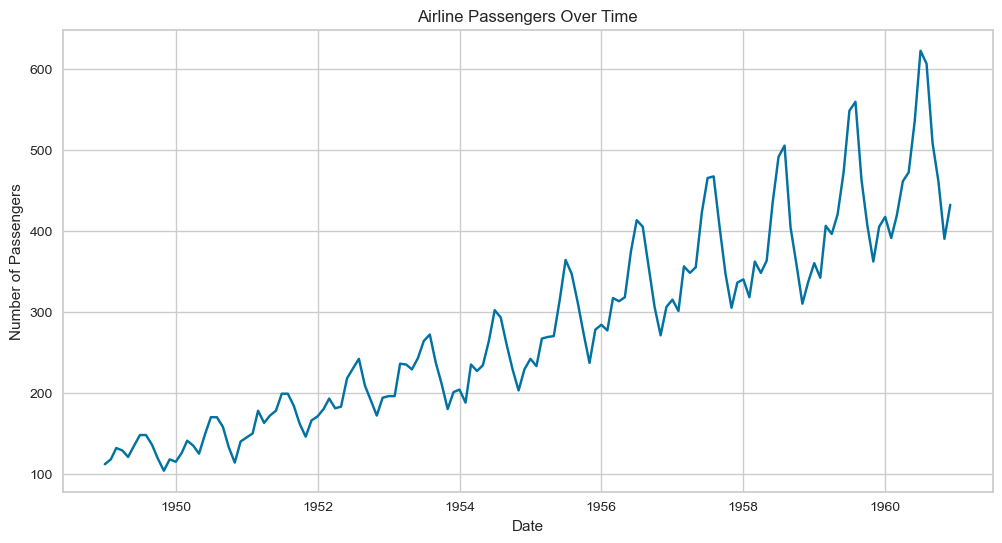

In [14]:

# Plot the time series
plt.figure(figsize=(12, 6))
plt.plot(data.index, data.values)
plt.title('Airline Passengers Over Time')
plt.xlabel('Date')
plt.ylabel('Number of Passengers')
plt.grid(True)
plt.show()


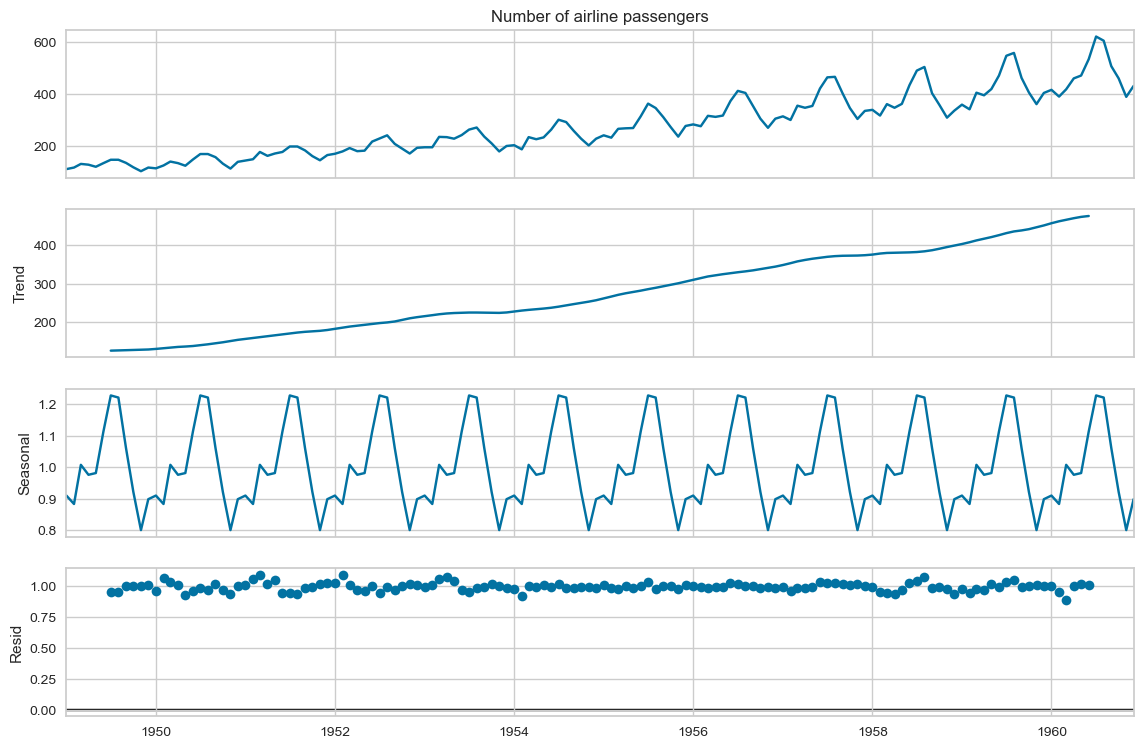

In [15]:

# Decompose the time series (trend, seasonal, residual)
from statsmodels.tsa.seasonal import seasonal_decompose
decomposition = seasonal_decompose(data, model='multiplicative', period=12)
fig = decomposition.plot()
fig.set_size_inches(12, 8)
plt.show()


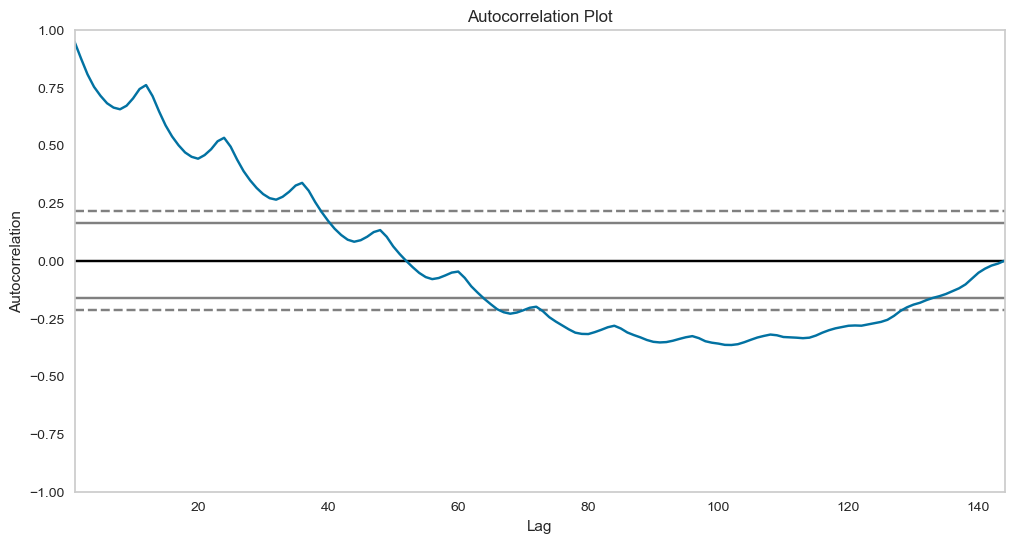

In [16]:

# Autocorrelation plot
from pandas.plotting import autocorrelation_plot
plt.figure(figsize=(12, 6))
autocorrelation_plot(data)
plt.title('Autocorrelation Plot')
plt.show()

## 3. Data Preprocessing and Feature Engineering

Handle missing values, outliers, and duplicates. Perform differencing if needed for stationarity. Create lag features and rolling window statistics. Split data into train, validation, and test sets.

#### Stationarity: 

* If your Augmented Dickey-Fuller (ADF) test shows the series is non-stationary, what level of differencing makes the most sense for your domain?

#### External Factors: 

* Would your forecast benefit from "Exogenous Variables" (e.g., weather data, holiday calendars, or marketing spend)?

In [17]:
# Data Preprocessing
# Ensure no missing values
data = data.dropna()

# Check for stationarity
from statsmodels.tsa.stattools import adfuller
result = adfuller(data.values)
print('ADF Statistic: %f' % result[0])
print('p-value: %f' % result[1])
if result[1] > 0.05:
    print("Time series is not stationary")
else:
    print("Time series is stationary")

# PyCaret will handle train/validation/test splits and feature engineering

ADF Statistic: 0.815369
p-value: 0.991880
Time series is not stationary


## 4. Setup PyCaret Environment for Time Series

Use pycaret.time_series.TSForecastingExperiment to setup the forecasting environment. Configure parameters like target variable, period, seasonal period, and fold strategy.

#### Forecast Horizon (fh): 

* Does the 12-month horizon used in the code match your planning cycle? 
* What is the maximum distance into the future you can predict before accuracy becomes unreliable?

#### Fold Strategy: 

* Why did you choose an "Expanding Window" versus a "Sliding Window" for cross-validation? 
* Which better represents how your data evolves?

In [ ]:
# Setup PyCaret Time Series Experiment
from pycaret.time_series import TSForecastingExperiment
exp = TSForecastingExperiment()
exp.setup(data, fh=12, fold=3, seasonal_period=12,n_jobs=1)

,Description,Value
0,session_id,8561
1,Target,Number of airline passengers
2,Approach,Univariate
3,Exogenous Variables,Not Present
4,Original data shape,"(144, 1)"
5,Transformed data shape,"(144, 1)"
6,Transformed train set shape,"(132, 1)"
7,Transformed test set shape,"(12, 1)"
8,Rows with missing values,0.0%
9,Fold Generator,ExpandingWindowSplitter


## 5. Train and Compare Multiple Forecasting Models

Use compare_models() to train and evaluate multiple time series models (ARIMA, ExponentialSmoothing, Prophet, AutoML models). Display model performance metrics and rankings.

#### Metric Prioritisation: 

* Which error metric matters most to your stakeholders? (e.g., is an under-prediction more "expensive" than an over-prediction?)

#### Complexity vs. Speed: 
* If a simple ExponentialSmoothing model performs similarly to a complex Auto ARIMA, which is easier for you to explain to your team?

In [19]:
# Compare models
best = exp.compare_models()

,Model,MASE,RMSSE,MAE,RMSE,MAPE,SMAPE,R2,TT (Sec)
exp_smooth,Exponential Smoothing,0.5716,0.5997,16.7772,19.7957,0.0422,0.0427,0.8954,0.5967
ets,ETS,0.5795,0.6105,17.0034,20.1451,0.0427,0.0433,0.8918,0.5767
et_cds_dt,Extra Trees w/ Cond. Deseasonalize & Detrending,0.6571,0.7169,19.3908,23.7345,0.0483,0.0482,0.8496,0.1233
huber_cds_dt,Huber w/ Cond. Deseasonalize & Detrending,0.6813,0.7866,20.0334,25.9670,0.0491,0.0499,0.8113,0.2433
arima,ARIMA,0.6830,0.6735,20.0069,22.2199,0.0501,0.0507,0.8677,0.6800
lr_cds_dt,Linear w/ Cond. Deseasonalize & Detrending,0.7004,0.7702,20.6084,25.4401,0.0509,0.0514,0.8215,0.4067
ridge_cds_dt,Ridge w/ Cond. Deseasonalize & Detrending,0.7004,0.7703,20.6086,25.4405,0.0509,0.0514,0.8215,0.2933
en_cds_dt,Elastic Net w/ Cond. Deseasonalize & Detrending,0.7029,0.7732,20.6816,25.5362,0.0511,0.0516,0.8201,0.2800
lasso_cds_dt,Lasso w/ Cond. Deseasonalize & Detrending,0.7048,0.7751,20.7373,25.6005,0.0512,0.0517,0.8193,0.7667
llar_cds_dt,Lasso Least Angular Regressor w/ Cond. Deseasonalize & Detrending,0.7048,0.7751,20.7366,25.6009,0.0512,0.0517,0.8192,0.0600


## 6. Select and Tune the Best Model

Select the best performing model using select_best_model(). Optionally tune hyperparameters using tune_model() to optimize forecasting accuracy.

In [37]:
# Select and tune the best model
best_model = exp.create_model(best)
tuned_model = exp.tune_model(best_model, optimize='MASE', n_iter=50, search_algorithm='grid')

,cutoff,MASE,RMSSE,MAE,RMSE,MAPE,SMAPE,R2
0,1956-12,0.4986,0.5736,14.5599,18.7744,0.0366,0.0376,0.8853
1,1957-12,0.5088,0.5368,15.5560,18.2253,0.0420,0.0411,0.9130
2,1958-12,0.7075,0.6887,20.2157,22.3876,0.0479,0.0494,0.8879
Mean,NaT,0.5716,0.5997,16.7772,19.7957,0.0422,0.0427,0.8954
SD,NaT,0.0962,0.0647,2.4651,1.8464,0.0046,0.0049,0.0125


,cutoff,MASE,RMSSE,MAE,RMSE,MAPE,SMAPE,R2
0,1956-12,0.3595,0.3926,10.4971,12.8526,0.0279,0.0278,0.9462
1,1957-12,0.9326,0.9578,28.5129,32.5168,0.0802,0.0761,0.7230
2,1958-12,0.3138,0.3540,8.9677,11.5075,0.0208,0.0209,0.9704
Mean,NaT,0.5353,0.5682,15.9926,18.9590,0.0429,0.0416,0.8799
SD,NaT,0.2816,0.2760,8.8752,9.6025,0.0265,0.0246,0.1114


Fitting 3 folds for each of 12 candidates, totalling 36 fits


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done  36 out of  36 | elapsed:    2.3s finished
[Parallel(n_jobs=-1)]: Done  36 out of  36 | elapsed:    2.3s finished


## 7. Generate Forecasts on Test Data

Use predict_model() to generate forecasts on the test dataset. Obtain point forecasts and confidence intervals for future periods.

In [ ]:
# Generate predictions
predictions = exp.predict_model(tuned_model)

,Model,MASE,RMSSE,MAE,RMSE,MAPE,SMAPE,R2
0,Exponential Smoothing,0.5855,0.6572,17.8284,22.7059,0.0375,0.0364,0.9069


## 8. Evaluate Model Performance and Metrics

Calculate and display evaluation metrics such as MAE, RMSE, MAPE, and other relevant time series metrics. Compare actual vs predicted values quantitatively.

#### Evaluation and Metrics

* Residual Analysis: 
    * Looking at the diagnostics plot, are the residuals "white noise" (random), or is there a pattern the model failed to capture?

* Business Impact: 
    * If your Mean Absolute Error (MAE) is X units, what does that translate to in terms of potential lost revenue or excess inventory costs?

In [ ]:
# Evaluate model performance
exp.plot_model(tuned_model, plot='forecast', data_kwargs={'conf_int': True})


print("Predictions:")
print(predictions.head())

Predictions:
           y_pred
1960-01  421.0968
1960-02  401.0273
1960-03  470.9919
1960-04  460.4348
1960-05  485.2349


In [ ]:
exp.plot_model(tuned_model, plot='diagnostics')


## 9. Visualise Actual vs Predicted Values

Create comprehensive visualisations showing actual time series data alongside model predictions. Include confidence intervals, residual plots, and error distribution analysis.

In [ ]:
# Additional visualisations
exp.plot_model(tuned_model, plot='residuals')
# predict confidence intervals with plot
exp.plot_model(tuned_model, plot='insample', data_kwargs={'conf_int': True})
# exp.plot_model(tuned_model, plot='insample')

## 10. Deploy and Make Future Predictions

Finalize the best model using finalize_model(). Make predictions for future periods beyond the dataset. Save the model for production deployment.

In [ ]:
# Finalise and deploy model
final_model = exp.finalize_model(tuned_model)
future_predictions = exp.predict_model(final_model, fh=24)
exp.save_model(final_model, 'airline_forecast_model')

print("Future predictions for the next 24 months:")
print(future_predictions.head())

Transformation Pipeline and Model Successfully Saved
Future predictions for the next 24 months:
           y_pred
1961-01  450.3144
1961-02  425.8160
1961-03  476.2059
1961-04  506.2143
1961-05  519.3188
